# Word Document

In [1]:
from langchain_community.document_loaders import Docx2txtLoader

docs_loader=Docx2txtLoader("docs/DevSecOps_Resume_updated.docx")

docs = docs_loader.load()

/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_18967/1608842497.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import Docx2txtLoader


In [2]:
docs

[Document(metadata={'source': 'docs/DevSecOps_Resume_updated.docx'}, page_content="Professional Summary\n\nDevSecOps Engineer with 8+ years in software development and 3 years focused on DevSecOps: building CI/CD pipelines, integrating security scanning (SAST, SCA, DAST, container scanning), and securing Kubernetes environments. Background in .NET, Python, and full-stack development across Insurance, HRMS, and E-commerce domains. Comfortable working end-to-end from pipeline design to cloud infrastructure security.\n\nCore Skills\n\nCI/CD & SCM: Git, GitHub Actions, Jenkins, branch strategy, reusable workflows\n\nSecurity Testing: SAST (SonarQube), SCA (pip-audit), DAST (OWASP ZAP), container scanning (Trivy)\n\nContainers & Kubernetes: Docker, Kubernetes (kind), Helm, Argo CD (GitOps), Kyverno policies, RBAC, NetworkPolicy\n\nCloud & IaC: AWS, Terraform, Checkov, CloudWatch, S3, HashiCorp Vault (secrets management)\n\nObservability: Prometheus, Grafana, ELK stack, incident response, pr

In [3]:
docs[0].page_content

"Professional Summary\n\nDevSecOps Engineer with 8+ years in software development and 3 years focused on DevSecOps: building CI/CD pipelines, integrating security scanning (SAST, SCA, DAST, container scanning), and securing Kubernetes environments. Background in .NET, Python, and full-stack development across Insurance, HRMS, and E-commerce domains. Comfortable working end-to-end from pipeline design to cloud infrastructure security.\n\nCore Skills\n\nCI/CD & SCM: Git, GitHub Actions, Jenkins, branch strategy, reusable workflows\n\nSecurity Testing: SAST (SonarQube), SCA (pip-audit), DAST (OWASP ZAP), container scanning (Trivy)\n\nContainers & Kubernetes: Docker, Kubernetes (kind), Helm, Argo CD (GitOps), Kyverno policies, RBAC, NetworkPolicy\n\nCloud & IaC: AWS, Terraform, Checkov, CloudWatch, S3, HashiCorp Vault (secrets management)\n\nObservability: Prometheus, Grafana, ELK stack, incident response, production support\n\nDevelopment: Python (Django, FastAPI), C# / .NET Core (ASP.NET

In [6]:
from langchain_community.document_loaders import UnstructuredWordDocumentLoader

unstuctre = UnstructuredWordDocumentLoader(
    "docs/DevSecOps_Resume_updated.docx",
    mode="elements"
)

In [9]:
docs = unstuctre.load()

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1


In [10]:
len(docs)

75

In [12]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter  = RecursiveCharacterTextSplitter(
    chunk_size = 500,
    chunk_overlap = 100
)

chunks = splitter.split_documents(docs)

In [14]:
len(chunks)

73

# csv and excel

In [15]:
import pandas as pd
import os 

os.makedirs("csv/structredfile",exist_ok=True)

In [16]:
data = {
    'Tool': ['Docker', 'Kubernetes', 'Jenkins', 'Terraform', 'Prometheus'],
    'Category': ['Containerization', 'Orchestration', 'CI/CD', 'Infrastructure as Code', 'Monitoring'],
    'Rating': [4.8, 4.9, 4.5, 4.7, 4.6],
    'Users': [95000, 120000, 78000, 65000, 72000],
    'Description': [
        'Platform for building and running applications in containers',
        'Container orchestration platform for automating deployments and scaling',
        'Automation server used for continuous integration and delivery',
        'Infrastructure as code tool for provisioning cloud resources',
        'Monitoring and alerting toolkit for cloud-native applications'
    ]
}

In [18]:
df=pd.DataFrame(data)

In [19]:
df

,Tool,Category,Rating,Users,Description
0,Docker,Containerization,4.8,95000,Platform for building and running applications...
1,Kubernetes,Orchestration,4.9,120000,Container orchestration platform for automatin...
2,Jenkins,CI/CD,4.5,78000,Automation server used for continuous integrat...
3,Terraform,Infrastructure as Code,4.7,65000,Infrastructure as code tool for provisioning c...
4,Prometheus,Monitoring,4.6,72000,Monitoring and alerting toolkit for cloud-nati...


In [21]:
df.to_csv("csv/structredfile/devops.csv",index=False)

In [26]:
from langchain_community.document_loaders import CSVLoader

csv_load = CSVLoader(
    file_path="csv/structredfile/devops.csv",
    encoding="utf-8",
    csv_args={
        'delimiter':','
    }

)

In [27]:
csv_doc = csv_load.load()

In [28]:
csv_doc

[Document(metadata={'source': 'csv/structredfile/devops.csv', 'row': 0}, page_content='Tool: Docker\nCategory: Containerization\nRating: 4.8\nUsers: 95000\nDescription: Platform for building and running applications in containers'),
 Document(metadata={'source': 'csv/structredfile/devops.csv', 'row': 1}, page_content='Tool: Kubernetes\nCategory: Orchestration\nRating: 4.9\nUsers: 120000\nDescription: Container orchestration platform for automating deployments and scaling'),
 Document(metadata={'source': 'csv/structredfile/devops.csv', 'row': 2}, page_content='Tool: Jenkins\nCategory: CI/CD\nRating: 4.5\nUsers: 78000\nDescription: Automation server used for continuous integration and delivery'),
 Document(metadata={'source': 'csv/structredfile/devops.csv', 'row': 3}, page_content='Tool: Terraform\nCategory: Infrastructure as Code\nRating: 4.7\nUsers: 65000\nDescription: Infrastructure as code tool for provisioning cloud resources'),
 Document(metadata={'source': 'csv/structredfile/devop

In [29]:
csv_doc[0].metadata

{'source': 'csv/structredfile/devops.csv', 'row': 0}

In [30]:
csv_doc[0].page_content

'Tool: Docker\nCategory: Containerization\nRating: 4.8\nUsers: 95000\nDescription: Platform for building and running applications in containers'

# Excel

In [31]:
from langchain_community.document_loaders import UnstructuredExcelLoader

excel_loader = UnstructuredExcelLoader(
    "EXCEL/inventory.xlsx",
    mode="single"
)

In [35]:
excel_doc = excel_loader.load()

In [36]:
excel_doc

[Document(metadata={'source': 'EXCEL/inventory.xlsx'}, page_content='Product Category Price Stock Description Laptop Electronics 999.99 50 High-performance laptop with 16GB RAM and 512GB SSD Mouse Accessories 29.99 200 Wireless optical mouse with ergonomic design Keyboard Accessories 79.99 150 Mechanical keyboard with RGB backlighting Monitor Electronics 299.99 75 27-inch 4K monitor with HDR support Webcam Electronics 89.99 100 1080p webcam with noise cancellation\n\nCategory Total_Items Total_Value Electronics 3 1389.97 Accessories 2 109.98')]

In [37]:
from langchain_community.document_loaders import UnstructuredExcelLoader

excel_loader = UnstructuredExcelLoader(
    "EXCEL/inventory.xlsx",
    mode="elements"
)

In [38]:
excel_doc = excel_loader.load()

In [39]:
excel_doc

[Document(metadata={'source': 'EXCEL/inventory.xlsx', 'file_directory': 'EXCEL', 'filename': 'inventory.xlsx', 'last_modified': '2026-10-22T20:37:01', 'page_name': 'Products', 'page_number': 1, 'text_as_html': '<table><tr><td>Product</td><td>Category</td><td>Price</td><td>Stock</td><td>Description</td></tr><tr><td>Laptop</td><td>Electronics</td><td>999.99</td><td>50</td><td>High-performance laptop with 16GB RAM and 512GB SSD</td></tr><tr><td>Mouse</td><td>Accessories</td><td>29.99</td><td>200</td><td>Wireless optical mouse with ergonomic design</td></tr><tr><td>Keyboard</td><td>Accessories</td><td>79.99</td><td>150</td><td>Mechanical keyboard with RGB backlighting</td></tr><tr><td>Monitor</td><td>Electronics</td><td>299.99</td><td>75</td><td>27-inch 4K monitor with HDR support</td></tr><tr><td>Webcam</td><td>Electronics</td><td>89.99</td><td>100</td><td>1080p webcam with noise cancellation</td></tr></table>', 'languages': ['eng'], 'filetype': 'application/vnd.openxmlformats-officedocum

In [40]:
splitter  = RecursiveCharacterTextSplitter(
    chunk_size = 500,
    chunk_overlap = 100
)

chunks = splitter.split_documents(excel_doc)

In [41]:
chunks

[Document(metadata={'source': 'EXCEL/inventory.xlsx', 'file_directory': 'EXCEL', 'filename': 'inventory.xlsx', 'last_modified': '2026-10-22T20:37:01', 'page_name': 'Products', 'page_number': 1, 'text_as_html': '<table><tr><td>Product</td><td>Category</td><td>Price</td><td>Stock</td><td>Description</td></tr><tr><td>Laptop</td><td>Electronics</td><td>999.99</td><td>50</td><td>High-performance laptop with 16GB RAM and 512GB SSD</td></tr><tr><td>Mouse</td><td>Accessories</td><td>29.99</td><td>200</td><td>Wireless optical mouse with ergonomic design</td></tr><tr><td>Keyboard</td><td>Accessories</td><td>79.99</td><td>150</td><td>Mechanical keyboard with RGB backlighting</td></tr><tr><td>Monitor</td><td>Electronics</td><td>299.99</td><td>75</td><td>27-inch 4K monitor with HDR support</td></tr><tr><td>Webcam</td><td>Electronics</td><td>89.99</td><td>100</td><td>1080p webcam with noise cancellation</td></tr></table>', 'languages': ['eng'], 'filetype': 'application/vnd.openxmlformats-officedocum

In [43]:
import numpy as np
import matplotlib.pyplot as plt


word_embedings = {
    "paradise": [0.9,0.3],
    "jailer2":[0.9,0.2],
    "MAD":[0.1,0.9],
    "wild wild punjab": [0.2,0.95]
}

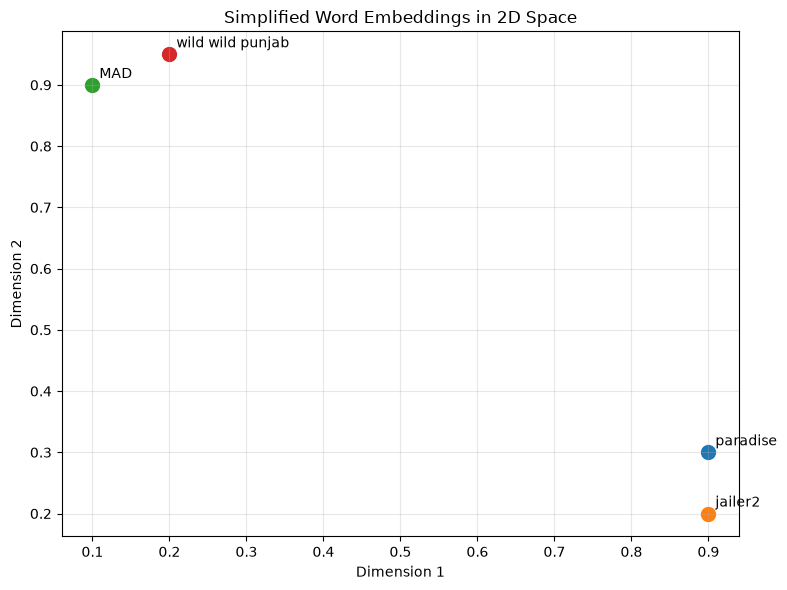

In [46]:
fig,ax = plt.subplots(figsize=(8,6))

for word,coords in word_embedings.items():
    ax.scatter(coords[0], coords[1], s=100)
    ax.annotate(word, (coords[0], coords[1]), xytext=(5, 5), 
                textcoords='offset points')

ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_title('Simplified Word Embeddings in 2D Space')
ax.grid(True, alpha=0.3)



plt.tight_layout()
plt.show()



In [ ]:
def cosine_similaity(vector1,vector2):
    dot_product = np.dot(vector1,vector2)
    norma_a = np.linalg.norm(vector1)
    norma_b = np.linalg.norm(vector2)  

    return dot_product/norma_a*norma_b

In [48]:
paradise = [0.9,0.3]
jailer2 = [0.9,0.2]
mad = [0.1,0.9]
wildwild = [0.2,0.95]

In [50]:
print(cosine_similaity(paradise,jailer2))

0.8454880247525687


In [51]:
print(cosine_similaity(paradise,wildwild))

0.47585252442327125


In [52]:
print(cosine_similaity(jailer2,mad))

0.2651924939049547
